# Radar vegetation phenology using Sentinel-1

* **Products used:** 
[s1_rtc](https://explorer.digitalearth.africa/s1_rtc), 
[crop_mask](https://explorer.digitalearth.africa/crop_mask)


In [1]:
%matplotlib inline

import datetime as dt
from datetime import datetime
import os

import datacube
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import mpl_toolkits.axisartist as AA
import numpy as np
import pandas as pd
from datacube.utils.aws import configure_s3_access
from odc.geo.geom import Geometry

from deafrica_tools.areaofinterest import define_area
from deafrica_tools.bandindices import dualpol_indices
from deafrica_tools.datahandling import load_ard
from deafrica_tools.plotting import display_map, rgb
from deafrica_tools.spatial import xr_rasterize
from deafrica_tools.temporal import xr_phenology
from mpl_toolkits.axes_grid1 import host_subplot

configure_s3_access(aws_unsigned=True, cloud_defaults=True)

In [2]:
dc = datacube.Datacube(app="Radar_vegetation_phenology")

In [3]:
lat = 7.31112
lon = -1.57730
buffer = 0.04

# Method 1: Specify the latitude, longitude, and buffer
aoi = define_area(lat, lon, buffer)

# Method 2: Use a polygon as a GeoJSON or Esri Shapefile.
# aoi = define_area(vector_path='aoi.shp')

# Create a geopolygon and geodataframe of the area of interest
geopolygon = Geometry(aoi["features"][0]["geometry"], crs="epsg:4326")
geopolygon_gdf = gpd.GeoDataFrame(geometry=[geopolygon], crs=geopolygon.crs)

# Get the latitude and longitude range of the geopolygon
lat_range = (geopolygon_gdf.total_bounds[1], geopolygon_gdf.total_bounds[3])
lon_range = (geopolygon_gdf.total_bounds[0], geopolygon_gdf.total_bounds[2])

# Set the range of dates for the analysis
time_range = ("2019-01-01", "2020-12-20")

#To use crop mask to filter result
use_crop_mask = False

## View the selected location
The next cell will display the selected area on an interactive map.
Feel free to zoom in and out to get a better understanding of the area you'll be analysing.
Clicking on any point of the map will reveal the latitude and longitude coordinates of that point.

In [4]:
display_map(x=lon_range, y=lat_range)

## Load Sentinel-1 data

The first step is to load Sentinel-1 data for the specified area of interest and time range. The `load_ard` function is used here to load data that has been masked using quality filters, making it ready for analysis.

In [5]:
# Create a reusable query
query = {
    "y": lat_range,
    "x": lon_range,
    "time": time_range,
    "measurements": ["vv", "vh"],
    "resolution": (-20, 20),
    "output_crs": "epsg:6933",
    "group_by": "solar_day",
}

# Load available data from Sentinel-1
ds = load_ard(
    dc=dc,
    products=["s1_rtc"],
    **query,
)

print(ds)

Using pixel quality parameters for Sentinel 1
Finding datasets
    s1_rtc
Applying pixel quality/cloud mask
Loading 119 time steps


/opt/venv/lib/python3.12/site-packages/deafrica_tools/datahandling.py:565: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.merge([ds_data, ds_masks])
/opt/venv/lib/python3.12/site-packages/rasterio/warp.py:385: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


<xarray.Dataset> Size: 187MB
Dimensions:      (time: 119, y: 508, x: 387)
Coordinates:
  * time         (time) datetime64[ns] 952B 2019-01-04T18:18:06.620072 ... 20...
  * y            (y) float64 4kB 9.353e+05 9.353e+05 ... 9.252e+05 9.252e+05
  * x            (x) float64 3kB -1.56e+05 -1.56e+05 ... -1.484e+05 -1.483e+05
    spatial_ref  int32 4B 6933
Data variables:
    vv           (time, y, x) float32 94MB 0.1169 0.09744 ... 0.2149 0.1539
    vh           (time, y, x) float32 94MB 0.06761 0.04554 ... 0.01838 0.02979
Attributes:
    crs:           EPSG:6933
    grid_mapping:  spatial_ref


### Clip the datasets to the shape of the area of interest
A geopolygon represents the bounds and not the actual shape because it is designed to represent the extent of the geographic feature being mapped, rather than the exact shape. In other words, the geopolygon is used to define the outer boundary of the area of interest, rather than the internal features and characteristics.

Clipping the data to the exact shape of the area of interest is important because it helps ensure that the data being used is relevant to the specific study area of interest. While a geopolygon provides information about the boundary of the geographic feature being represented, it does not necessarily reflect the exact shape or extent of the area of interest.

In [6]:
# Rasterise the area of interest polygon
aoi_raster = xr_rasterize(gdf=geopolygon_gdf, da=ds, crs=ds.crs)
# Mask the dataset to the rasterised area of interest
ds = ds.where(aoi_raster == 1)

## Mask region with DE Africa's cropland extent map

Load the cropland mask over the region of interest.

In [7]:
if use_crop_mask:
    cm = dc.load(
        product="crop_mask",
        time=("2019"),
        measurements="filtered",
        resampling="nearest",
        like=ds.geobox,
    ).filtered.squeeze()

    cm.where(cm < 255).plot.imshow(
        add_colorbar=False, figsize=(6, 6)
    )  # we filter to <255 to omit missing data
    plt.title("Cropland Extent");

Now we will use the cropland map to mask the regions in the Sentinel-1 data that only have cropping.

In [8]:
# Filter out the no-data pixels (255) and non-crop pixels (0) from the cropland map and
# mask the Sentinel-1 data.
if use_crop_mask:
    ds = ds.where(cm == 1)

### False colour RGB plots
Now can plot some of the Sentinel-1 images as false colour images using the `rgb` function. Notice that the backscatter intensity of the cropping regions is changing throughout the year as the plants in the fields go through their growth and senescence cycle.

In [9]:
# VH/VV will help create an RGB image
ds["vh/vv"] = ds.vh / ds.vv

# median values are used to scale the measurements so they have a similar range for visualization
med_s1 = ds[["vv", "vh", "vh/vv"]].median()

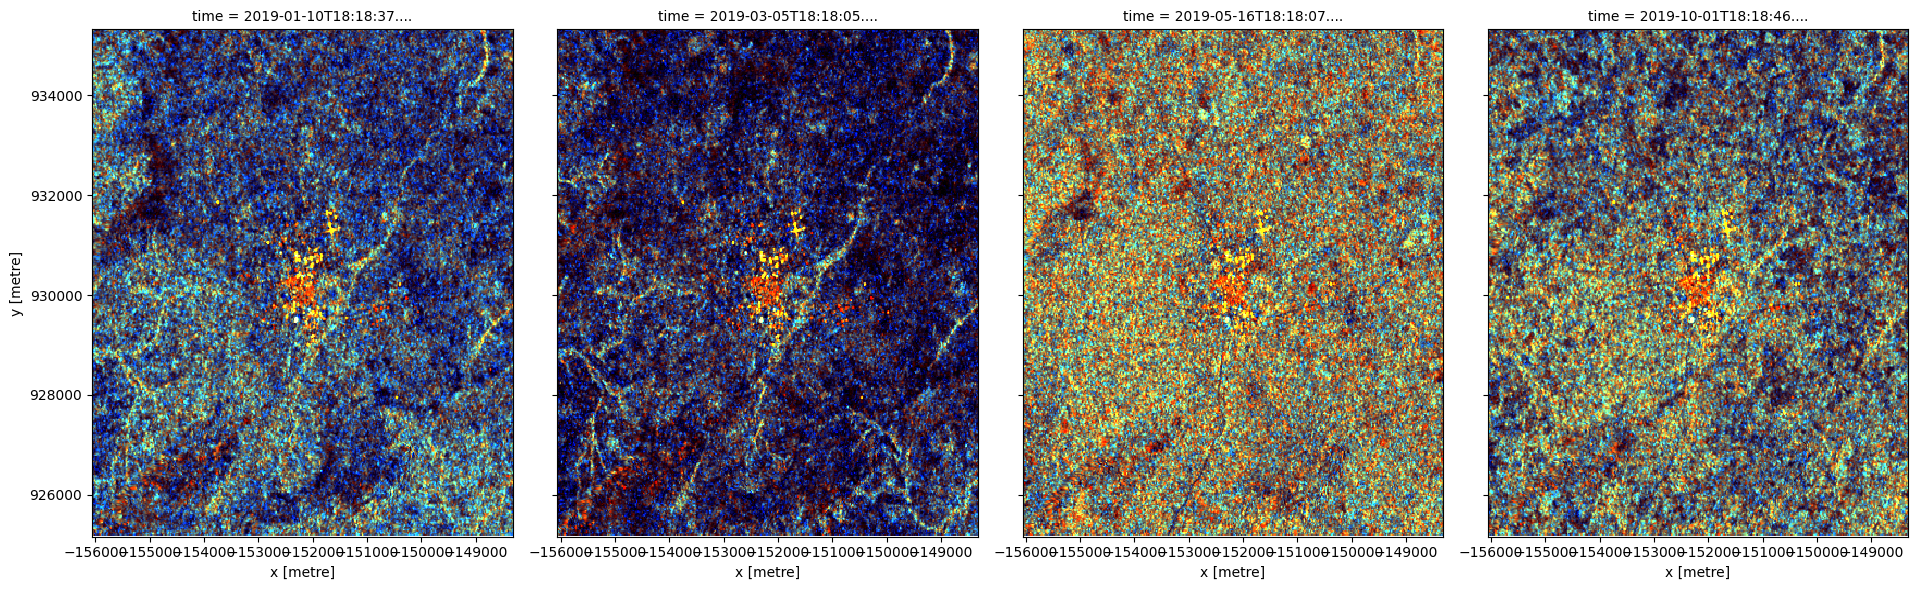

In [10]:
# plotting an RGB image for selected timesteps
time_steps = [1, 10, 22, 45]

rgb(
    ds[["vv", "vh", "vh/vv"]] / med_s1,  # normalize image ranges
    bands=["vv", "vh", "vh/vv"],
    index=time_steps,
    col_wrap=4,
);

## Compute the radar vegetation index

This study measures the presence of vegetation through either the `Radar vegetation index (RVI)`.
 
The formula is

        RVI = 4*VH/(VV+VH)

RVI is available through the `dualpol_indices` function, imported from [deafrica_tools.bandindices](../Tools/deafrica_tools/bandindices.py).

In [11]:
# Calculate the chosen vegetation proxy index and add it to the loaded data set
ds = dualpol_indices(ds, index="RVI")

## Plot the vegetation index over time

To get an idea of how the vegetation health changes throughout the year(s), we can plot a zonal time series over the region of interest. First we will do a simple plot of the zonal mean of the data.  


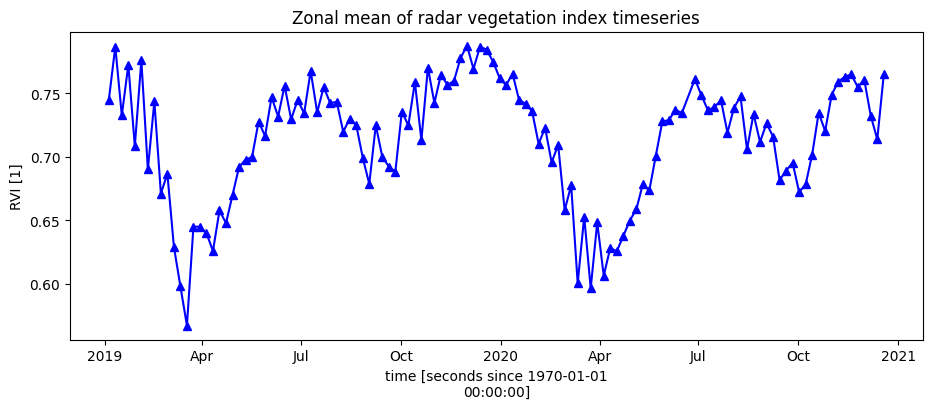

In [12]:
ds.RVI.mean(["x", "y"]).plot.line("b-^", figsize=(11, 4))
plt.title("Zonal mean of radar vegetation index timeseries");

## Smoothing/Interpolating vegetation time-series

Here, we will smooth and interpolate the data to ensure we working with a consistent time-series. This is a very important step in the workflow and there are many ways to smooth, interpolate, gap-fill, remove outliers, or curve-fit the data to ensure a useable time-series. If not using the default example, you may have to define additional methods to those used here.

To do this we take two steps:

1. Resample the data to fortnightly time-steps using the fortnightly median
2. Calculate a rolling mean with a window of 4 steps


In [13]:
resample_period = "2W"
window = 4

rvi_smooth = (
    ds.RVI.resample(time=resample_period)
    .median()
    .rolling(time=window, min_periods=1)
    .mean()
)

Plot the smoothed and interpolated time-series

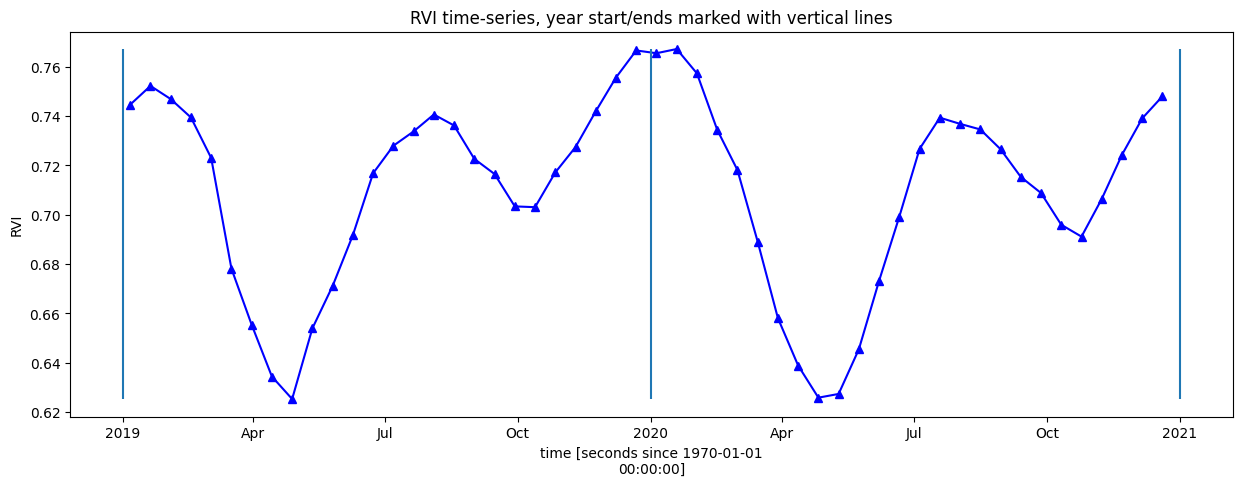

In [14]:
rvi_smooth_1D = rvi_smooth.mean(["x", "y"])
rvi_smooth_1D.plot.line("b-^", figsize=(15, 5))
_max = rvi_smooth_1D.max()
_min = rvi_smooth_1D.min()
plt.vlines(np.datetime64("2019-01-01"), ymin=_min, ymax=_max)
plt.vlines(np.datetime64("2020-01-01"), ymin=_min, ymax=_max)
plt.vlines(np.datetime64("2021-01-01"), ymin=_min, ymax=_max)
plt.title("RVI time-series, year start/ends marked with vertical lines")
plt.ylabel("RVI");

## Calculate phenology statistics using `xr_phenology`

The DE Africa function `xr_phenology` can calculate a number of land-surface phenology statistics that together describe the characteristics of a plant's lifecycle.  The function can calculate the following statistics on either a zonal timeseries (like the one above), or on a per-pixel basis:

        SOS = Date of start of season
        POS = Date of peak of season
        EOS = Date of end of season
        vSOS = Value at start of season
        vPOS = Value at peak of season
        vEOS = Value at end of season
        Trough = Minimum value of season
        LOS = Length of season (Days)
        AOS = Amplitude of season (in value units)
        ROG = Rate of greening
        ROS = Rate of senescence

By default the function will return all the statistics as an `xarray.Dataset`, to return only a subset of these statistics pass a list of the desired statistics to the function e.g. `stats=['SOS', 'EOS', 'ROG']`.

See the [deafrica_tools.temporal](../Tools/deafrica_tools/temporal.py) script for more information on each of the parameters in `xr_phenology`.


### Zonal phenology statistics

To help us understand what these statistics refer too, lets first pass the simpler zonal mean (mean of all pixels in the image) time-series to the function and plot the results on the same curves as above.

First, provide a list of statistics to calculate with the parameter, `pheno_stats`.

`method_sos` : If 'first' then vSOS is estimated as the first positive slope on the greening side of the curve. If 'median', then vSOS is estimated as the median value of the postive slopes on the greening side of the curve.

`method_eos` : If 'last' then vEOS is estimated as the last negative slope on the senescing side of the curve. If 'median', then vEOS is estimated as the 'median' value of the negative slopes on the senescing side of the curve.

In [15]:
pheno_stats = [
    "SOS",
    "vSOS",
    "POS",
    "vPOS",
    "EOS",
    "vEOS",
    "Trough",
    "LOS",
    "AOS",
    "ROG",
    "ROS",
]
method_sos = "first"
method_eos = "last"

In [16]:
# find all the years to assist with plotting
years = rvi_smooth_1D.groupby("time.year")

# store results in dict
pheno_results = {}

# loop through years and calculate phenology
for y, year in years:
    # calculate stats
    stats = xr_phenology(
        year,
        method_sos=method_sos,
        method_eos=method_eos,
        stats=pheno_stats,
        verbose=False,
    )
    # add results to dict
    pheno_results[str(y)] = stats

df_dict = {}
for key, value in pheno_results.items():
    df_dict_1 = {}
    for b in value.data_vars:
        if value[b].dtype == np.dtype("<M8[ns]") or value[b].dtype == np.dtype("int16"):
            result = pd.to_datetime(value[b].values)
        else:
            result = round(float(value[b].values), 3)
        df_dict_1[b] = result
    df_dict[key] = df_dict_1
            
df = (pd.DataFrame(df_dict)).T
df

,SOS,vSOS,POS,vPOS,EOS,vEOS,Trough,LOS,AOS,ROG,ROS
2019,2019-04-28 00:00:00,0.625,2019-12-22 00:00:00,0.767,NaT,NaN,0.625,0.0,0.141,0.001,NaN
2020,NaT,NaN,2020-01-19 00:00:00,0.767,2020-04-26 00:00:00,0.626,0.626,0.0,0.141,NaN,-0.001


Plot the results with our statistcs annotated on the plot

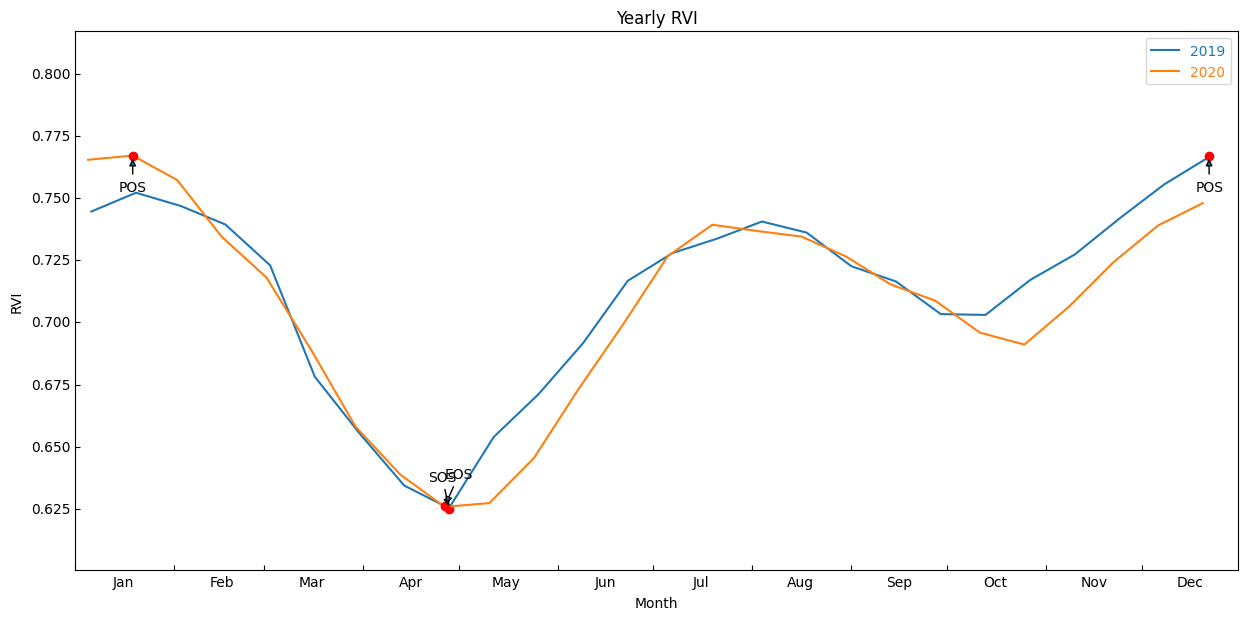

In [17]:
# Figure to which the subplot will be added
fig = plt.figure(figsize=(15, 7))
# Create a subplot that can act as a host to parasitic axes
host = host_subplot(111, figure=fig, axes_class=AA.Axes)


# Function to use to edit the axes of the plot
def adjust_axes(ax):
    # Set the location of the major and minor ticks.
    ax.xaxis.set_major_locator(mpl.dates.MonthLocator())
    ax.xaxis.set_minor_locator(mpl.dates.MonthLocator(bymonthday=16))

    # Format the major and minor tick labels.
    ax.xaxis.set_major_formatter(mpl.ticker.NullFormatter())
    ax.xaxis.set_minor_formatter(mpl.dates.DateFormatter("%b"))

    # Turn off unnecessary ticks.
    ax.axis["bottom"].minor_ticks.set_visible(False)

    ax.axis["top"].major_ticks.set_visible(False)
    ax.axis["top"].minor_ticks.set_visible(False)

    ax.axis["right"].major_ticks.set_visible(False)
    ax.axis["right"].minor_ticks.set_visible(False)


# Find all the years to assist with plotting
years = rvi_smooth_1D.groupby("time.year")

# Counter to aid in plotting.
counter = 0

for y, year in years:
    # Grab all the values we need for plotting.
    eos = df.loc[str(y)].EOS
    sos = df.loc[str(y)].SOS
    pos = df.loc[str(y)].POS

    veos = df.loc[str(y)].vEOS
    vsos = df.loc[str(y)].vSOS
    vpos = df.loc[str(y)].vPOS

    if counter == 0:
        ax = host
    else:
        # Create the secondary axis.
        ax = host.twiny()

    # Plot the data
    year.plot(ax=ax, label=y)

    # add start of season
    ax.plot(sos, vsos, "or")
    ax.annotate(
        "SOS",
        xy=(sos, vsos),
        xytext=(-15, 20),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="-|>"),
    )

    # add end of season
    ax.plot(eos, veos, "or")
    ax.annotate(
        "EOS",
        xy=(eos, veos),
        xytext=(0, 20),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="-|>"),
    )

    # add peak of season
    ax.plot(pos, vpos, "or")
    ax.annotate(
        "POS",
        xy=(pos, vpos),
        xytext=(-10, -25),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="-|>"),
    )

    # Set the x-axis limits
    min_x = dt.date(y, 1, 1)
    max_x = dt.date(y, 12, 31)
    ax.set_xlim(min_x, max_x)

    adjust_axes(ax)

    counter += 1

host.legend(labelcolor="linecolor")
host.set_ylim([_min - 0.025, _max.values + 0.05])

plt.xlabel("Month")
plt.ylabel("RVI")
plt.title("Yearly RVI");

In [23]:
from scipy.signal import find_peaks

s = rvi_smooth_1D.to_series()
peaks, _ = find_peaks(s.values, prominence=0.01)
troughs, _ = find_peaks(-s.values, prominence=0.01)

print("Peaks:\n", s.iloc[peaks].round(3))
print("\nTroughs:\n", s.iloc[troughs].round(3))

Peaks:
 time
2019-08-04    0.741
2020-01-19    0.767
2020-07-19    0.739
Name: RVI, dtype: float32

Troughs:
 time
2019-04-28    0.625
2019-10-13    0.703
2020-04-26    0.626
2020-10-25    0.691
Name: RVI, dtype: float32


## Per-pixel phenology statistics

We can now calculate the statistics for every pixel in our time-series and plot the results.

In [18]:
# find all the years to assist with plotting
years = rvi_smooth.groupby("time.year")

# get list of years in ts to help with looping
years_int = [y[0] for y in years]

# store results in dict
pheno_results = {}

# loop through years and calculate phenology
for year in years_int:
    # select year
    da = dict(years)[year]

    # calculate stats
    stats = xr_phenology(
        da,
        method_sos=method_sos,
        method_eos=method_eos,
        stats=pheno_stats,
        verbose=False,
    )
    # add results to dict
    pheno_results[str(year)] = stats

The phenology statistics have been calculated seperately for every pixel in the image.  Let's plot each of them to see the results. 

Below, pick a year from the phenology results to plot. 

In [19]:
# Pick a year to plot
year_to_plot = "2019"

At the top if the plotting code we re-mask the phenology results with the crop-mask. This is because `xr_phenology`has methods for handling pixels with only NaNs (such as those regions outside of the polygon mask), so the results can have phenology results for regions outside the mask. We will therefore have to mask the data again.


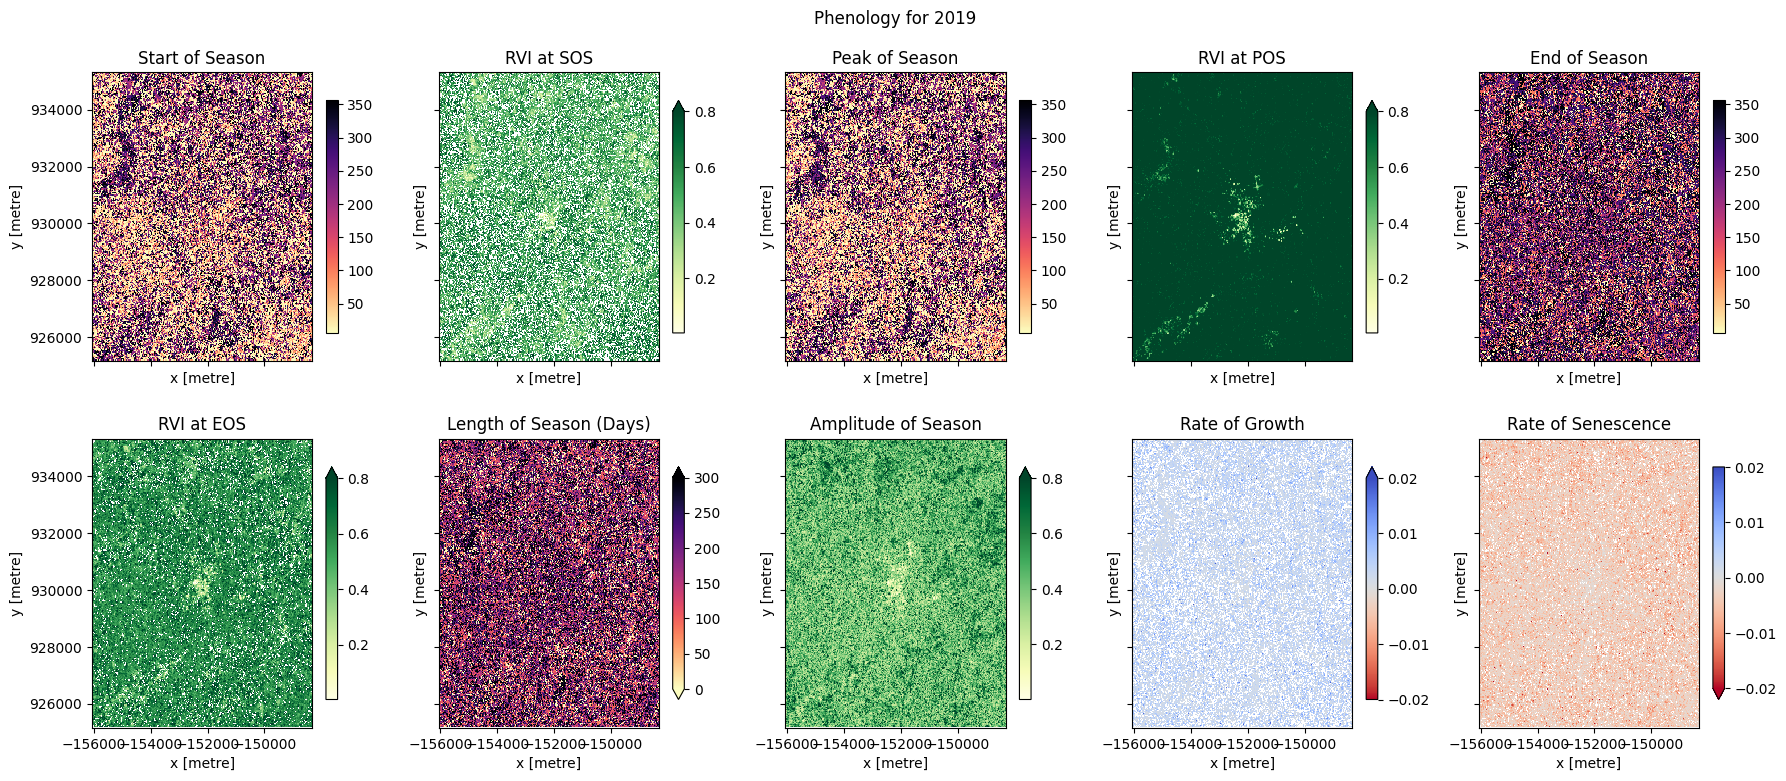

In [20]:
# select the year to plot
phen = pheno_results[year_to_plot]

# Define a few items to aid in plotting.
start_date = dt.date(int(year_to_plot), 1, 1)
end_date = dt.date(int(year_to_plot), 10, 27)

date_list = pd.date_range(start_date, end_date, freq="MS")
bounds = [int(i.strftime("%Y%m%d")) for i in date_list]


@mpl.ticker.FuncFormatter
def float_to_date(x, pos):
    tick_str = str(int(x))
    year = tick_str[:4]
    month = tick_str[4:6]
    day = tick_str[6:]
    return f"{year}-{month}-{day}"


# set up figure
fig, ax = plt.subplots(nrows=2,
                       ncols=5,
                       figsize=(18, 8),
                       sharex=True,
                       sharey=True)

# set colorbar size
cbar_size = 0.7

# set aspect ratios
for a in fig.axes:
    a.set_aspect("equal")

# start of season
# Convert SOS values from np.date64 to float values for plotting
cax = phen.POS.dt.dayofyear.plot(
    ax=ax[0, 0],
    cmap="magma_r",
    add_colorbar=True,
    cbar_kwargs=dict(shrink=cbar_size, label=None),
)
ax[0, 0].set_title("Start of Season")

phen.vSOS.plot(ax=ax[0, 1],
               cmap="YlGn",
               vmax=0.8,
               cbar_kwargs=dict(shrink=cbar_size, label=None))
ax[0, 1].set_title("RVI at SOS")

# peak of season
# # Convert POS values from np.date64 to float values for plotting
cax = phen.POS.dt.dayofyear.plot( 
    ax=ax[0, 2],
    cmap="magma_r",
    add_colorbar=True,
    cbar_kwargs=dict(shrink=cbar_size, label=None),
)
ax[0, 2].set_title("Peak of Season")

phen.vPOS.plot(ax=ax[0, 3],
               cmap="YlGn",
               vmax=0.8,
               cbar_kwargs=dict(shrink=cbar_size, label=None))
ax[0, 3].set_title("RVI at POS")

# end of season
# Convert EOS values from np.date64 to float values for plotting
cax = phen.EOS.dt.dayofyear.plot(     
    ax=ax[0, 4],
    cmap="magma_r",
    add_colorbar=True,
    cbar_kwargs=dict(shrink=cbar_size, label=None),
)
ax[0, 4].set_title("End of Season")

phen.vEOS.plot(ax=ax[1, 0],
               cmap="YlGn",
               vmax=0.8,
               cbar_kwargs=dict(shrink=cbar_size, label=None))
ax[1, 0].set_title("RVI at EOS")

# Length of Season
phen.LOS.plot(
    ax=ax[1, 1],
    cmap="magma_r",
    vmax=300,
    vmin=0,
    cbar_kwargs=dict(shrink=cbar_size, label=None),
)
ax[1, 1].set_title("Length of Season (Days)")

# Amplitude
phen.AOS.plot(ax=ax[1, 2],
              cmap="YlGn",
              vmax=0.8,
              cbar_kwargs=dict(shrink=cbar_size, label=None))
ax[1, 2].set_title("Amplitude of Season")

# rate of growth
phen.ROG.plot(
    ax=ax[1, 3],
    cmap="coolwarm_r",
    vmin=-0.02,
    vmax=0.02,
    cbar_kwargs=dict(shrink=cbar_size, label=None),
)
ax[1, 3].set_title("Rate of Growth")

# rate of Sensescence
phen.ROS.plot(
    ax=ax[1, 4],
    cmap="coolwarm_r",
    vmin=-0.02,
    vmax=0.02,
    cbar_kwargs=dict(shrink=cbar_size, label=None),
)
ax[1, 4].set_title("Rate of Senescence")
plt.suptitle("Phenology for " + year_to_plot)
plt.tight_layout();

## Conclusions

In the example above, we can see most of the fields are following a similar cropping schedule and are therefore likely the same species of crop. We can also observe that some fields have not followed this schedule (e.g. the EOY plot shows some fields didn't follow this schedule, probably because they either remained fallow during the year, or because there were two peaks during the year which may have confused the phenology stats).  Differences in the rates of growth, and in the RVI values at different times of the season, may be attributable to differences in soil quality, watering intensity, or other farming practices. 

Phenology statistics are a powerful way to summarise the seasonal cycle of a plant's life.  Per-pixel plots of phenology can help us understand the timing of vegetation growth and sensecence across large areas and across diverse plant species as every pixel is treated as an independent series of observations. This could be important, for example, if we wanted to assess how the growing seasons are shifting as the climate warms.  


---

## Additional information

<b> License </b> The code in this notebook is licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0).

Digital Earth Africa data is licensed under the [Creative Commons by Attribution 4.0](https://creativecommons.org/licenses/by/4.0/) license.

<b> Contact </b> If you need assistance, please post a question on the [DE Africa Slack channel](https://digitalearthafrica.slack.com/) or on the [GIS Stack Exchange](https://gis.stackexchange.com/questions/ask?tags=open-data-cube) using the `open-data-cube` tag (you can view previously asked questions [here](https://gis.stackexchange.com/questions/tagged/open-data-cube)).

If you would like to report an issue with this notebook, you can file one on [Github](https://github.com/digitalearthafrica/deafrica-sandbox-notebooks).

<b> Compatible datacube version </b>

In [21]:
print(datacube.__version__)

1.9.13


**Last Tested:**

In [22]:
from datetime import datetime

datetime.today().strftime("%Y-%m-%d")

'2026-10-14'